# 03 — Contrôles et expérience d'apprentissage automatique

Ce notebook rassemble **ce qu'on peut et ne peut pas dire** de l'indice : contrôle avec l'eau détectée par radar, six quartiers cités, et un modèle d'apprentissage automatique.
Il lit les fichiers `outputs/*.csv` produits par :

```
python -m src.models.validate_s1     # contrôle de l'indice par le radar
python -m src.models.validation      # quartiers de référence
python -m src.models.train           # expérience d'apprentissage automatique
```

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

# Racine du projet : le notebook peut être lancé depuis notebooks/ ou depuis la racine.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs"
plt.rcParams["figure.dpi"] = 110


def load(name, folder=PROC):
    """Lit un raster (bande 1) en float, les valeurs « sans donnée » deviennent NaN."""
    with rasterio.open(folder / name) as src:
        arr = src.read(1).astype("float64")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
    return arr


def show(arr, title, cmap="viridis", vmin=None, vmax=None, ax=None):
    ax = ax or plt.gca()
    im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
    plt.colorbar(im, ax=ax, shrink=0.75)

## 1. L'indice face à l'eau détectée par radar

Positifs : pixels avec eau sur au moins 2 dates. Négatifs : jamais détectés, hors eau permanente. **AUC** = probabilité qu'un pixel inondé ait un score plus haut qu'un pixel non détecté (0,5 = hasard).

In [2]:
v = pd.read_csv(OUT / "validation_s1.csv")
table = v.pivot_table(index="variable", columns="strate", values="auc").round(2)
order = ["indice multicritère", "composante fluviale", "composante locale",
         "critère seul : height", "critère seul : distance", "critère seul : slope", "critère seul : twi"]
table.loc[[o for o in order if o in table.index]]

strate,hors zone bâtie,plaine basse (hauteur <= 15 m),toute la zone,zone bâtie seulement
variable,,,,
indice multicritère,0.96,0.71,0.93,0.89
composante fluviale,0.99,0.84,0.98,0.99
composante locale,0.75,0.59,0.71,0.65
critère seul : height,0.99,0.95,1.00,1.00
critère seul : distance,0.95,0.77,0.93,0.96
critère seul : slope,0.78,0.60,0.73,0.63
critère seul : twi,0.66,0.57,0.64,0.64


**Lecture honnête.**
- La hauteur au-dessus du Niger sépare presque parfaitement les pixels détectés (AUC 1,00) : c'est **circulaire**. Les pixels détectés sont ceux que le fleuve vient de couvrir, donc ceux qui sont juste au-dessus de l'eau.
- Le test « plaine basse » (hauteur ≤ 15 m) est plus sévère : la composante fluviale y garde 0,84, la composante locale tombe à 0,59.
- Les poids n'ont **pas** été ajustés pour améliorer ces chiffres.

## 2. Six quartiers cités comme inondés

Pour chaque quartier : score moyen du disque de 500 à 600 m, et son percentile parmi les zones bâties (100 = plus exposé que tout le reste de la zone bâtie).

In [3]:
q = pd.read_csv(OUT / "validation_results.csv")
cols = [c for c in ["name", "score_moyen", "pct_total", "pct_height", "pct_distance", "pct_slope", "pct_twi", "robustesse"] if c in q.columns]
q[cols].round(2)

,name,score_moyen,pct_total,pct_height,pct_distance,pct_slope,pct_twi,robustesse
0,Missabougou,0.70,84.2,90.2,84.7,43.2,43.6,0.53
1,Niamakoro,0.72,91.5,60.9,86.6,85.8,86.4,0.62
2,Banconi,0.72,89.6,82.1,97.1,53.8,45.0,0.58
3,Lafiabougou,0.56,43.7,65.3,16.8,56.9,49.3,0.17
4,Taliko,0.56,43.3,59.5,80.3,17.1,18.1,0.25
5,Kalabambougou,0.66,69.8,82.1,20.6,93.2,86.7,0.37


Percentile moyen : 70 (50 attendu au hasard)


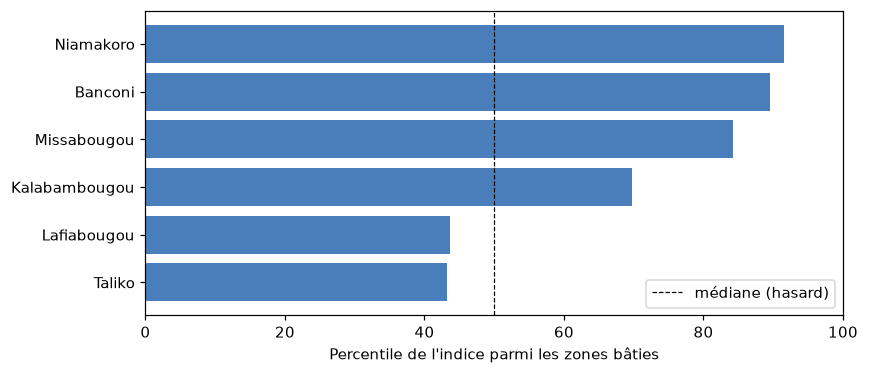

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
q_sorted = q.sort_values("pct_total")
ax.barh(q_sorted["name"], q_sorted["pct_total"], color="#4a7ebb")
ax.axvline(50, color="k", ls="--", lw=0.8, label="médiane (hasard)")
ax.set_xlabel("Percentile de l'indice parmi les zones bâties")
ax.set_xlim(0, 100)
ax.legend()
plt.tight_layout()
print(f"Percentile moyen : {q['pct_total'].mean():.0f} (50 attendu au hasard)")

**Lecture honnête.** Quatre quartiers sur six sont bien ou assez bien classés, deux sont sous la médiane (Lafiabougou, Taliko). Six points choisis parce qu'ils sont célèbres pour avoir été inondés, **sans aucun lieu non inondé** : on ne peut pas calculer d'AUC, et ce n'est pas une validation. Les hypothèses pour les deux échecs (drainage artificiel absent, canaux manquants dans OSM, bruit du modèle de surface, point trop approximatif) sont **à vérifier**, pas démontrées.

## 3. Un modèle d'apprentissage automatique fait-il mieux ?

Boosting de gradient et régression logistique, entraînés à prédire l'eau détectée par radar, avec **validation spatiale par blocs de 3 km** (un bloc entier est soit en entraînement, soit en test).

Pour relancer l'entraînement (quelques minutes) : décommenter la ligne ci-dessous.

In [5]:
# from src.models import train; train.run()
m = pd.read_csv(OUT / "model_s1_results.csv")
m[["variable / modèle", "AUC toute la zone", "AUC plaine basse", "précision moyenne toute la zone"]].round(3)

,variable / modèle,AUC toute la zone,AUC plaine basse,précision moyenne toute la zone
0,hauteur seule (sans modèle),0.996,0.952,0.629
1,distance seule (sans modèle),0.933,0.770,0.101
2,composante fluviale (sans modèle),0.985,0.841,0.376
3,indice combiné (sans modèle),0.926,0.705,0.246
4,boosting : 4 critères,0.997,0.960,0.699
5,régression logistique : 4 critères,0.996,0.955,0.653
6,boosting : sans hauteur,0.954,0.821,0.240
7,boosting : pente + TWI seulement,0.713,0.588,0.112
8,boosting : 4 critères + bâti,0.997,0.965,0.722


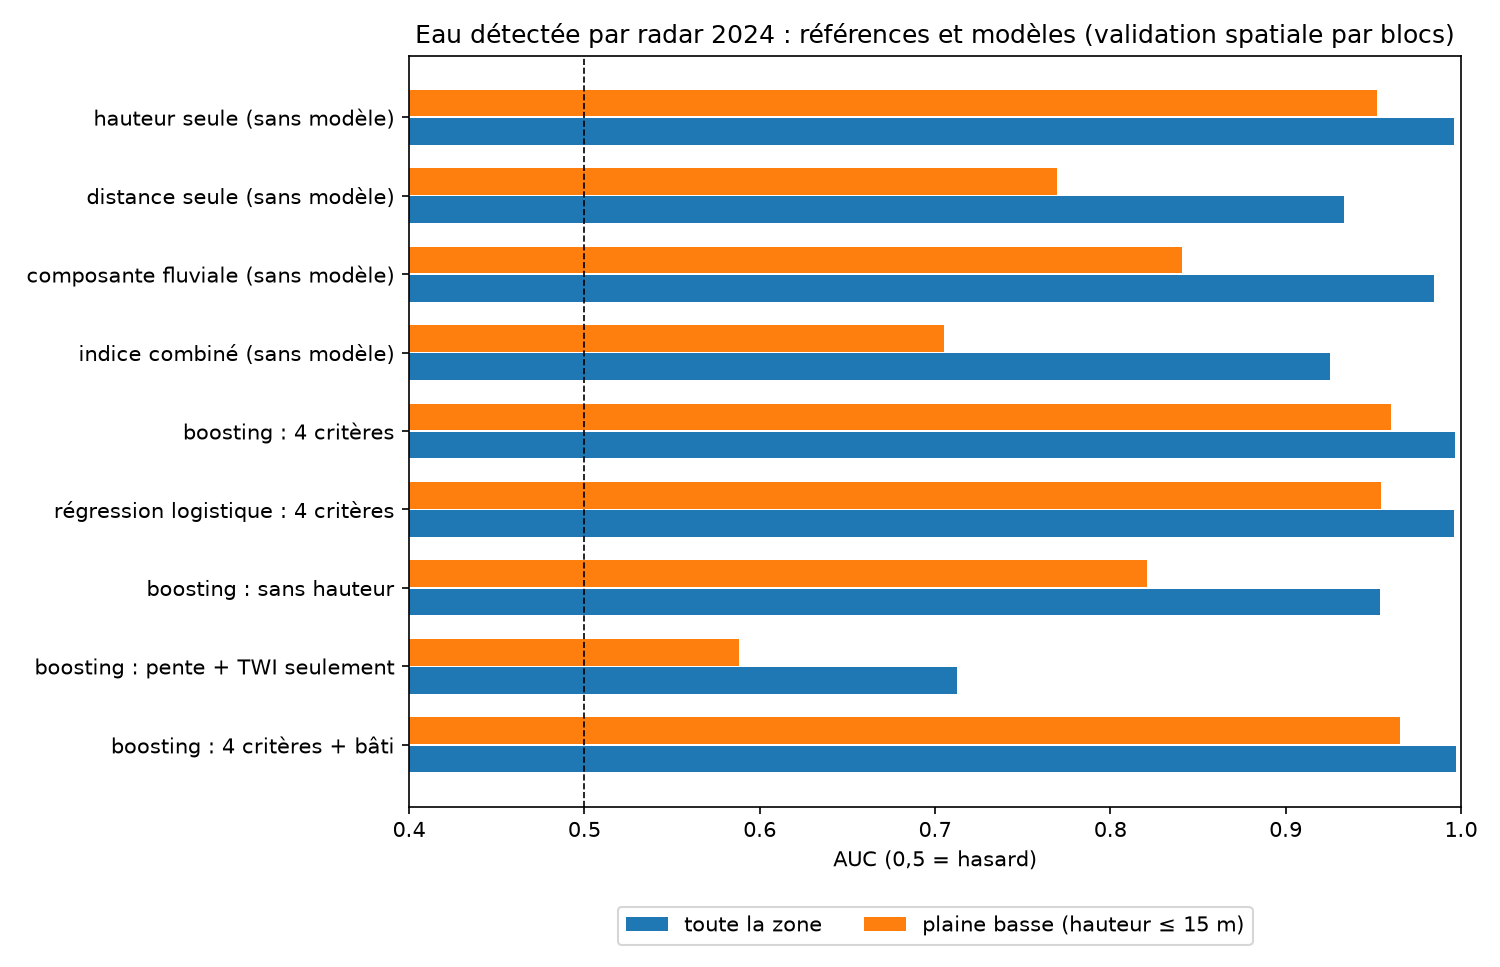

In [6]:
from IPython.display import Image, display
display(Image(filename=str(OUT / "figures" / "model_s1.png")))

**Lecture.**
- Le modèle n'améliore pas nettement la hauteur seule en AUC (plaine basse : 0,960 contre 0,952). La précision moyenne monte un peu (0,63 à 0,70) : modeste, sans intervalle de confiance.
- La régression logistique fait presque aussi bien que le boosting : la relation est simple.
- Pente et TWI seuls plafonnent à 0,59 : même appris, ils ne prédisent pas l'eau fluviale.
- Le modèle prédit **l'eau du fleuve détectée par radar**, pas l'inondation des quartiers : on ne le retient pas comme résultat principal.

## Synthèse pour la soutenance

| Question | Réponse | Niveau de preuve |
|---|---|---|
| Où l'indice est-il élevé ? | Près du fleuve, en terrain bas et plat | Cartes (notebook 02) |
| Dépend-il des poids ? | Peu (corrélations 0,95–0,99) | Analyse de sensibilité |
| Cohérent avec l'eau vue par radar ? | Oui pour la composante fluviale (0,98 ; 0,84 en plaine basse) | Partiellement circulaire |
| Composante locale (pente + TWI) validée ? | **Non** | Aucune étiquette d'inondation urbaine |
| Quartiers cités comme inondés ? | 4 sur 6 bien ou assez bien classés | Six points, pas de négatifs |
| Un modèle apprend-il mieux ? | Non, pas de gain décisif | Validation spatiale par blocs |

**Ce qui manque** : des emprises d'inondation en ville et des lieux non inondés connus. Avec eux, la même expérience (références simples, validation par blocs) pourrait être refaite.